# Задание 3.2. Кластеризация изображений тканей
Королев Даниил, группа 636-02.

Разделил изображения PathMNIST на девять кластеров без использования меток.
Сравнил два представления: пиксели после PCA и признаки цвета, расположения
цветовых пятен и текстуры. Представление выбираю по silhouette, а метки
читаю только после фиксации кластеров и внешних назначений.
Условие: https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/blob/main/task/task3-2_images_unsupervised_clustering.md

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform

import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import Markdown, display
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED, N_CLUSTERS, SILHOUETTE_SAMPLE = 42, 9, 1000
THREAD_LIMITER = threadpool_limits(limits=1)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=0.9)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150})
ROOT = Path.cwd()
if not (ROOT / "dataset/task3_2/train.npz").exists():
    ROOT = ROOT.parent
assert (ROOT / "dataset/task3_2/train.npz").exists(), "Запустите код внутри репозитория"
OUT = ROOT / "outputs/task3_2_analysis"
OUT.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    plt.savefig(OUT / name, bbox_inches="tight")
    if get_ipython() is not None:
        plt.show()
    plt.close()

## Изображения без меток
Сначала читаю только images и image_id. Число кластеров взял из условия.
Пиксели перевёл из uint8 в [0, 1]. Картинки ниже выбраны равномерно по
порядку архива, без отбора по классам.

Обучающих изображений: 3600, форма: (28, 28, 3).


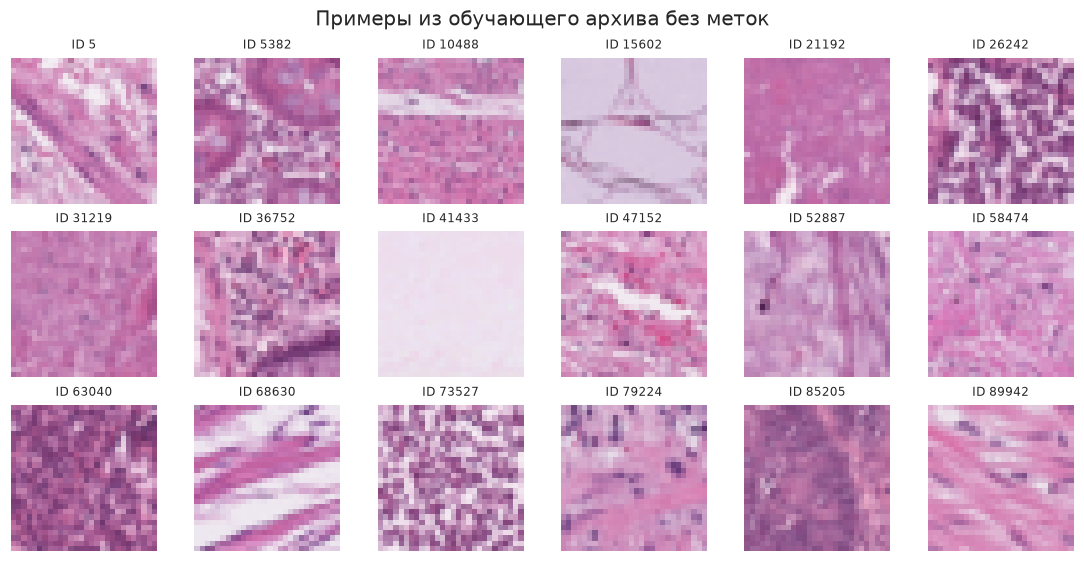

In [2]:
train_path = ROOT / "dataset/task3_2/train.npz"
external_path = ROOT / "dataset/task3_2/test_features.npz"
with np.load(train_path, allow_pickle=False) as archive:
    images = archive["images"]
    image_ids = archive["image_id"]
assert images.dtype == np.uint8 and images.shape[1:] == (28, 28, 3)
assert len(np.unique(image_ids)) == len(images)
pixels = images.astype(np.float32) / 255.0
print(f"Обучающих изображений: {len(images)}, форма: {images.shape[1:]}.")
fig, axes = plt.subplots(3, 6, figsize=(10, 5), layout="constrained")
for ax, idx in zip(axes.flat, np.linspace(0, len(images) - 1, 18, dtype=int)):
    ax.imshow(images[idx])
    ax.set_title(f"ID {image_ids[idx]}", fontsize=8)
    ax.axis("off")
fig.suptitle("Примеры из обучающего архива без меток")
save_figure("unlabelled_examples.png")

## Два представления
Первый вариант — распрямлённые RGB-пиксели и PCA до 50 компонент.
Второй — 92 признака: средние, STD и квантили по каналам, цветовые
гистограммы, средний цвет в сетке 4×4, изменения яркости и её энтропия.
Во втором варианте применяю StandardScaler и сохраняю 95% дисперсии через PCA.

В обоих случаях KMeans использует девять кластеров и 30 инициализаций.
Для выбора сравниваю silhouette на одной случайной подвыборке из 1000
обучающих изображений. Это оценка компактности в выбранном пространстве,
а не проверка правильности типов ткани.

In [3]:
def color_texture_features(batch):
    x = np.asarray(batch, dtype=np.float32)
    assert x.shape[1:] == (28, 28, 3)
    means = x.mean(axis=(1, 2))
    deviations = x.std(axis=(1, 2))
    quantiles = np.quantile(x, [0.1, 0.5, 0.9], axis=(1, 2)).transpose(1, 0, 2).reshape(len(x), -1)
    histograms = np.array([
        np.concatenate([np.histogram(image[:, :, c], bins=8, range=(0, 1))[0] / (28 * 28)
                        for c in range(3)]) for image in x
    ])
    spatial = x.reshape(len(x), 4, 7, 4, 7, 3).mean(axis=(2, 4)).reshape(len(x), -1)
    gray = x.mean(axis=3)
    dx, dy = np.abs(np.diff(gray, axis=2)), np.abs(np.diff(gray, axis=1))
    texture = np.column_stack([dx.mean(axis=(1, 2)), dx.std(axis=(1, 2)),
                               dy.mean(axis=(1, 2)), dy.std(axis=(1, 2))])
    hist_gray = np.array([np.histogram(image, bins=16, range=(0, 1))[0] / (28 * 28) for image in gray])
    entropy = -(hist_gray * np.log(np.maximum(hist_gray, 1e-12))).sum(axis=1) / np.log(16)
    result = np.column_stack([means, deviations, quantiles, histograms, spatial, texture, entropy])
    assert result.shape == (len(x), 92) and np.isfinite(result).all()
    return result


sample_idx = np.random.default_rng(SEED).choice(len(images), min(SILHOUETTE_SAMPLE, len(images)), replace=False)
np.save(OUT / "silhouette_sample_indices.npy", sample_idx)
representations = {"Пиксели + PCA50": pixels.reshape(len(images), -1),
                   "Цвет и текстура + PCA95%": color_texture_features(pixels)}
variants = {}
for name, features in representations.items():
    if name == "Пиксели + PCA50":
        scaler = None
        scaled = features
        pca = PCA(n_components=50, svd_solver="randomized", random_state=SEED).fit(scaled)
    else:
        scaler = StandardScaler().fit(features)
        scaled = scaler.transform(features)
        pca = PCA(n_components=0.95, svd_solver="full").fit(scaled)
    embedding = pca.transform(scaled)
    kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=30, random_state=SEED).fit(embedding)
    score = silhouette_score(embedding[sample_idx], kmeans.labels_[sample_idx])
    variants[name] = {"scaler": scaler, "pca": pca, "embedding": embedding,
                      "model": kmeans, "clusters": kmeans.labels_.copy(), "silhouette": float(score)}
    print(f"{name}: компонент {embedding.shape[1]}, silhouette={score:.3f}")
selected_name = max(variants, key=lambda name: variants[name]["silhouette"])
selected = variants[selected_name]
clusters = selected["clusters"]
cluster_sizes = np.bincount(clusters, minlength=N_CLUSTERS)
pd.DataFrame({"Кластер": np.arange(N_CLUSTERS), "Число изображений": cluster_sizes}).to_csv(OUT / "cluster_sizes.csv", index=False)
print("Выбран вариант до чтения меток:", selected_name)
selection_table = pd.DataFrame({name: {"Компоненты": r["embedding"].shape[1], "Silhouette": r["silhouette"]}
                                for name, r in variants.items()}).T
display(selection_table.round(3))

Пиксели + PCA50: компонент 50, silhouette=0.118
Цвет и текстура + PCA95%: компонент 21, silhouette=0.220
Выбран вариант до чтения меток: Цвет и текстура + PCA95%


,Компоненты,Silhouette
Пиксели + PCA50,50.0,0.118
Цвет и текстура + PCA95%,21.0,0.220


## Внешние назначения
Представление, PCA и центры KMeans уже выбраны. Для внешних изображений
выполняю только transform и predict. Тестовые изображения не участвуют
в обучении нормализации или выборе представления.

In [4]:
with np.load(external_path, allow_pickle=False) as archive:
    external_images = archive["images"]
    external_ids = archive["image_id"]
assert external_images.dtype == np.uint8 and external_images.shape[1:] == (28, 28, 3)
assert len(np.unique(external_ids)) == len(external_ids)
assert set(external_ids).isdisjoint(image_ids)
external_pixels = external_images.astype(np.float32) / 255.0
if selected_name == "Пиксели + PCA50":
    external_features = external_pixels.reshape(len(external_images), -1)
else:
    external_features = color_texture_features(external_pixels)
if selected["scaler"] is not None:
    external_features = selected["scaler"].transform(external_features)
external_embedding = selected["pca"].transform(external_features)
submission = pd.DataFrame({"image_id": external_ids, "prediction": selected["model"].predict(external_embedding)})
assert len(submission) == len(external_ids) and not submission.isna().any().any()
np.testing.assert_array_equal(submission.image_id, external_ids)
submission.to_csv(ROOT / "outputs/task3_2_predictions.csv", index=False)
frozen_predictions_hash = hashlib.sha256((ROOT / "outputs/task3_2_predictions.csv").read_bytes()).hexdigest()
np.savez(OUT / "pipeline.npz", representation=np.array(selected_name),
         scaler_mean=selected["scaler"].mean_ if selected["scaler"] is not None else np.array([]),
         scaler_scale=selected["scaler"].scale_ if selected["scaler"] is not None else np.array([]),
         pca_mean=selected["pca"].mean_, pca_components=selected["pca"].components_,
         centers=selected["model"].cluster_centers_)
print(f"Сохранено {len(submission)} назначений. Метки пока не читались.")

Сохранено 900 назначений. Метки пока не читались.


## Оценка после обучения
Теперь открываю метки и считаю ARI и NMI. Даже если другой вариант получит
больший ARI, выбранный по silhouette метод не меняю. ID кластера не является
ID ткани: для интерпретации использую таблицу «класс–кластер».

In [5]:
with np.load(train_path, allow_pickle=False) as archive:
    labels = archive["prediction"]
    label_names = archive["label_names"].astype(str)
metric_rows = []
for name, result in variants.items():
    metric_rows.append({"Вариант": name, "ARI": adjusted_rand_score(labels, result["clusters"]),
                        "NMI": normalized_mutual_info_score(labels, result["clusters"]),
                        "Silhouette": result["silhouette"], "Компоненты": result["embedding"].shape[1],
                        "Выбран": name == selected_name})
metric_table = pd.DataFrame(metric_rows).set_index("Вариант")
metric_table.to_csv(OUT / "metrics.csv")
display(metric_table.round(3))
composition = pd.crosstab(pd.Series(labels, name="Класс"), pd.Series(clusters, name="Кластер"))
composition = composition.reindex(index=range(9), columns=range(9), fill_value=0)
composition.to_csv(OUT / "class_cluster.csv")
pd.DataFrame({"image_id": image_ids, "target": labels, "prediction": clusters}).to_csv(OUT / "training_assignments.csv", index=False)

,ARI,NMI,Silhouette,Компоненты,Выбран
Вариант,,,,,
Пиксели + PCA50,0.149,0.282,0.118,50,False
Цвет и текстура + PCA95%,0.188,0.333,0.220,21,True


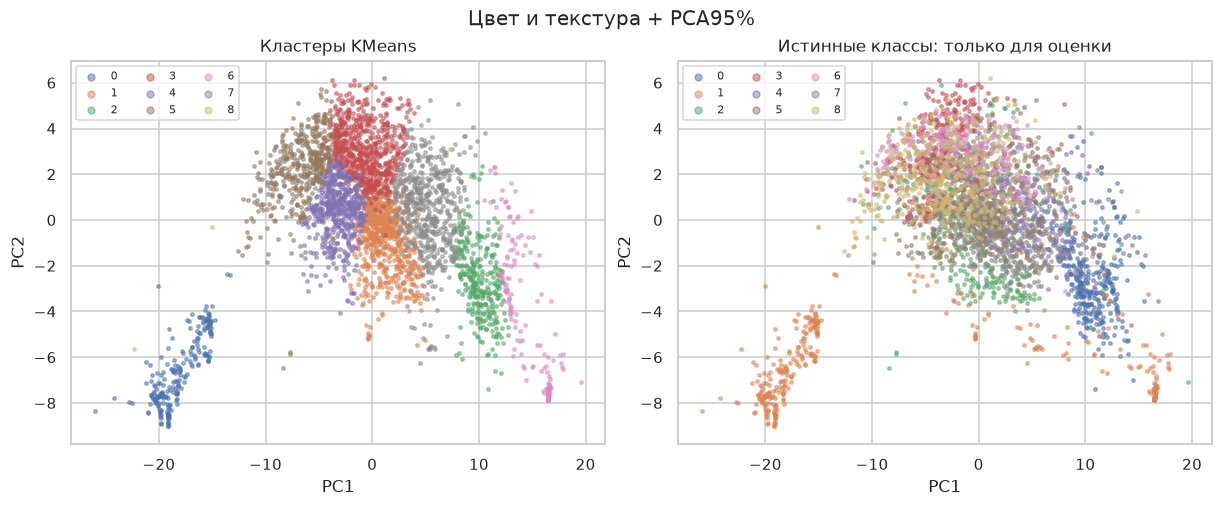

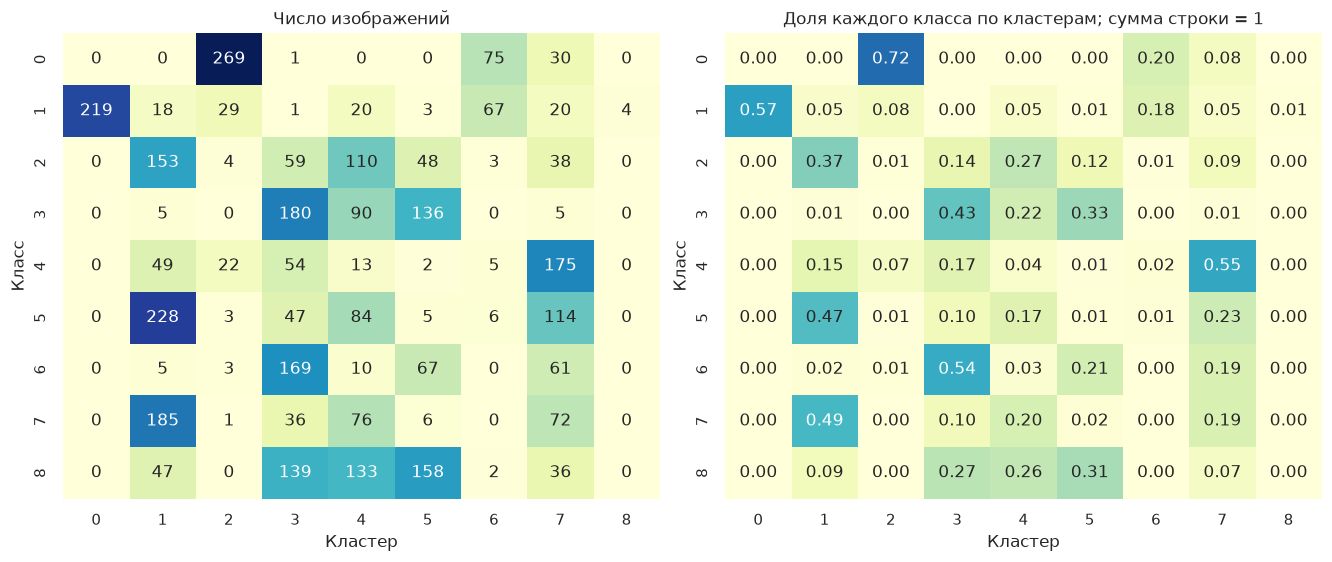

In [6]:
projection = selected["embedding"][:, :2]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for c in range(9):
    mask_cluster, mask_class = clusters == c, labels == c
    axes[0].scatter(projection[mask_cluster, 0], projection[mask_cluster, 1], s=5, alpha=0.5, label=str(c))
    axes[1].scatter(projection[mask_class, 0], projection[mask_class, 1], s=5, alpha=0.5, label=str(c))
for ax, title in zip(axes, ["Кластеры KMeans", "Истинные классы: только для оценки"]):
    ax.set(xlabel="PC1", ylabel="PC2", title=title)
    ax.legend(ncol=3, fontsize=7, markerscale=2)
fig.suptitle(selected_name)
save_figure("pca_comparison.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
sns.heatmap(composition, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=axes[0])
normalized_composition = composition.div(composition.sum(axis=1), axis=0)
sns.heatmap(normalized_composition, annot=True, fmt=".2f", cmap="YlGnBu", cbar=False, vmin=0, vmax=1, ax=axes[1])
axes[0].set_title("Число изображений")
axes[1].set_title("Доля каждого класса по кластерам; сумма строки = 1")
save_figure("class_cluster.png")

## Центры и примеры
Сначала показал центры KMeans в первых восьми компонентах. Средние картинки
ниже — средние RGB-изображения членов кластера, а не восстановленные ткани.
Для примеров взял по три изображения, ближайших к соответствующему центру.

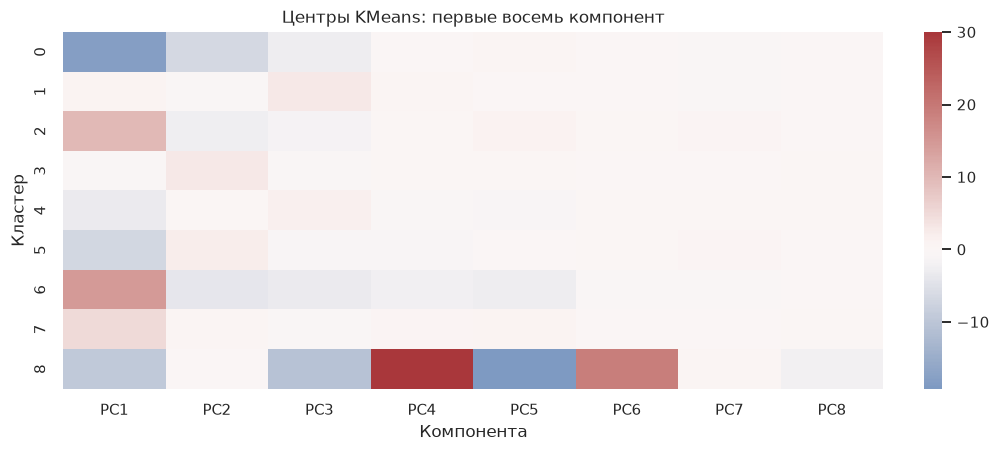

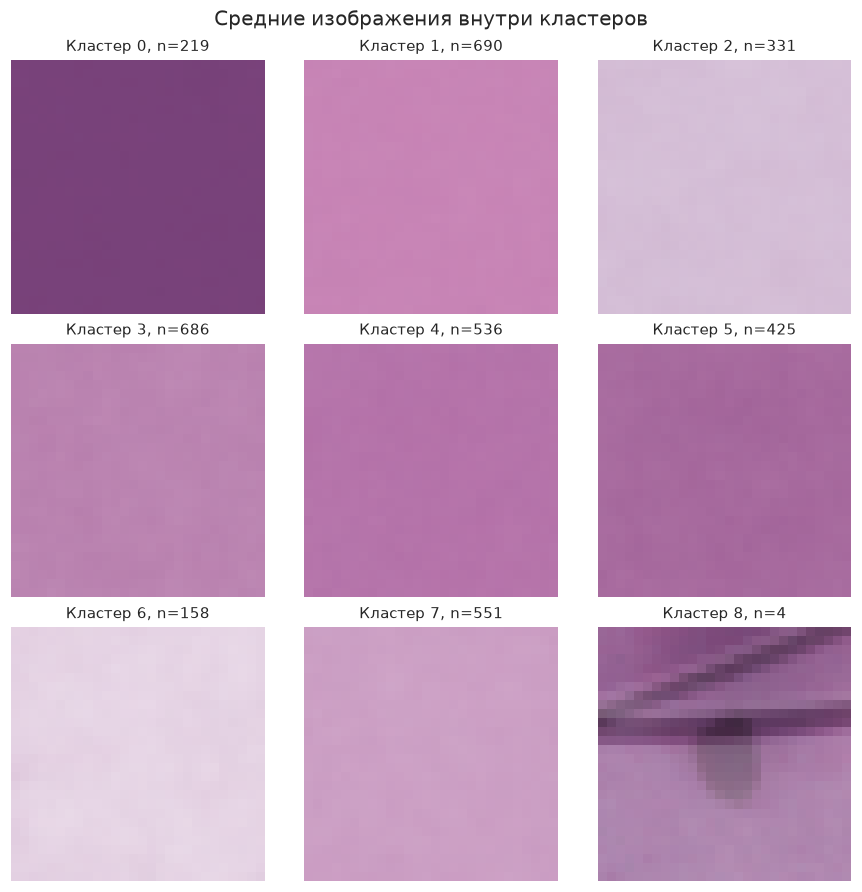

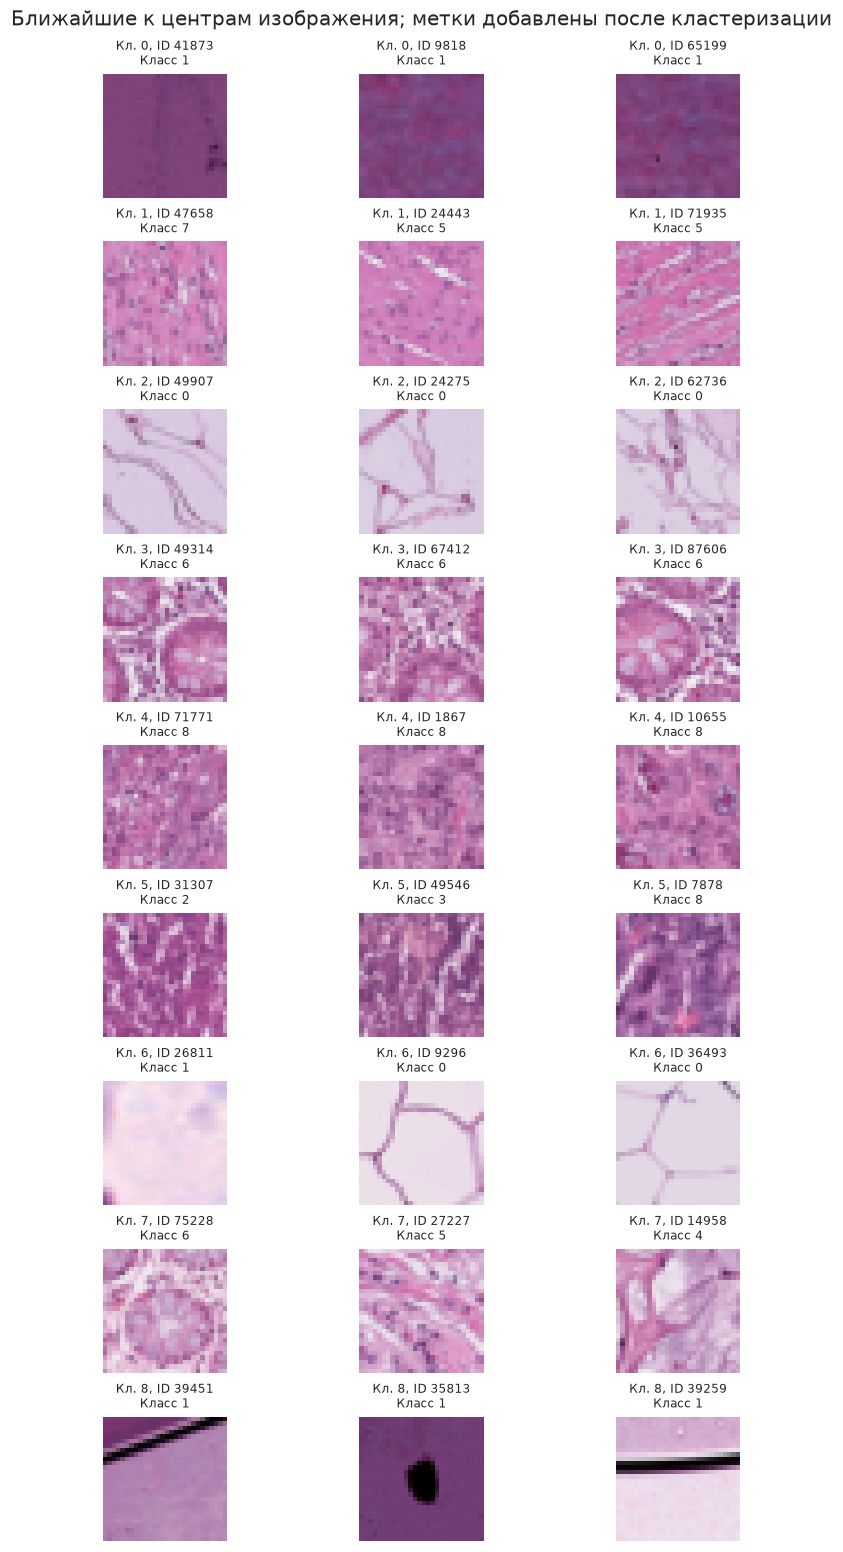

In [7]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sns.heatmap(selected["model"].cluster_centers_[:, :8], cmap="vlag", center=0, ax=ax,
            xticklabels=[f"PC{i+1}" for i in range(8)])
ax.set(xlabel="Компонента", ylabel="Кластер", title="Центры KMeans: первые восемь компонент")
save_figure("feature_centers.png")

fig, axes = plt.subplots(3, 3, figsize=(8, 8), layout="constrained")
for cluster_id, ax in enumerate(axes.flat):
    mask = clusters == cluster_id
    ax.imshow(images[mask].mean(axis=0).clip(0, 255).astype(np.uint8))
    ax.set_title(f"Кластер {cluster_id}, n={mask.sum()}", fontsize=10)
    ax.axis("off")
fig.suptitle("Средние изображения внутри кластеров")
save_figure("mean_images.png")

fig, axes = plt.subplots(9, 3, figsize=(7, 14), layout="constrained")
for cluster_id in range(9):
    idx = np.flatnonzero(clusters == cluster_id)
    distances = np.linalg.norm(selected["embedding"][idx] - selected["model"].cluster_centers_[cluster_id], axis=1)
    for ax, row in zip(axes[cluster_id], idx[np.argsort(distances)[:3]]):
        ax.imshow(images[row])
        ax.set_title(f"Кл. {cluster_id}, ID {image_ids[row]}\nКласс {labels[row]}", fontsize=8)
    for ax in axes[cluster_id]:
        ax.axis("off")
fig.suptitle("Ближайшие к центрам изображения; метки добавлены после кластеризации")
save_figure("cluster_examples.png")

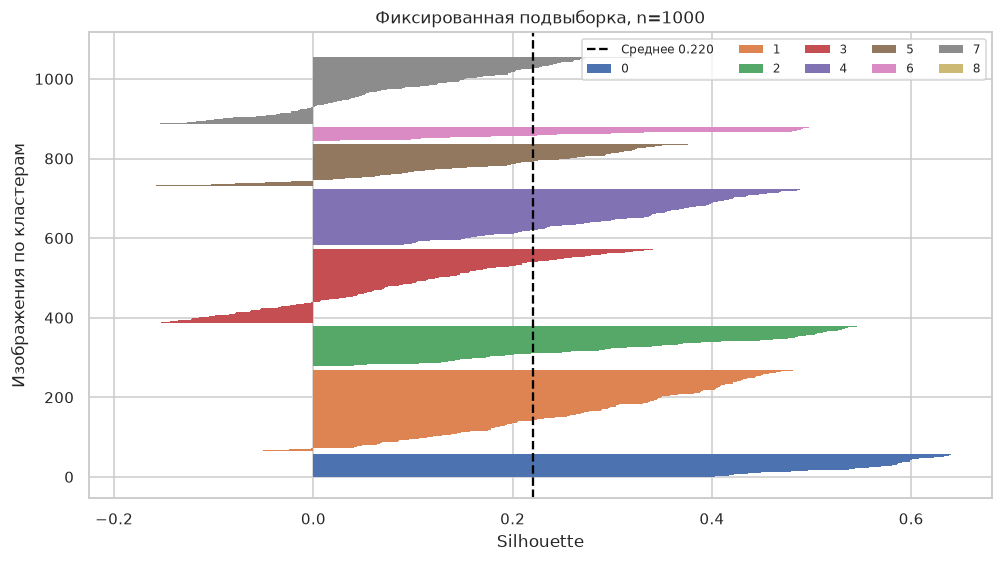

In [8]:
sample_labels = clusters[sample_idx]
sample_silhouettes = silhouette_samples(selected["embedding"][sample_idx], sample_labels)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
position = 0
for c in range(9):
    values = np.sort(sample_silhouettes[sample_labels == c])
    ax.barh(np.arange(position, position + len(values)), values, label=str(c), height=1,
            edgecolor="none", linewidth=0)
    position += len(values) + 8
ax.axvline(selected["silhouette"], linestyle="--", color="black", label=f"Среднее {selected['silhouette']:.3f}")
ax.set(xlabel="Silhouette", ylabel="Изображения по кластерам", title=f"Фиксированная подвыборка, n={len(sample_idx)}")
ax.legend(ncol=5, fontsize=8)
save_figure("silhouette.png")

## Выводы
Кластеризация не обязана повторить девять типов ткани. Она может прежде
всего разделить изображения по цвету или яркости. Поэтому рядом с
silhouette показываю ARI, NMI, состав кластеров и сами изображения.

In [9]:
main_metrics = metric_table.loc[selected_name]
report = (
    "Королев Даниил, 636-02. Задание 3.2.\n\n"
    f"Взял {len(images)} RGB-изображений 28×28. Сравнил PCA50 по пикселям с "
    "92 признаками цвета и текстуры (статистики RGB, гистограммы, сетка 4×4, "
    "градиенты яркости и энтропия). Для второго варианта использовал "
    "StandardScaler и PCA с 95% дисперсии. Все преобразования обучены только на train.\n\n"
    "В обоих вариантах KMeans, k=9, n_init=30, seed=42. Метки тканей не "
    "читались при извлечении признаков, обучении и выборе. По silhouette "
    f"на фиксированной случайной подвыборке из {len(sample_idx)} изображений "
    f"выбрал «{selected_name}», число компонент {selected['embedding'].shape[1]}. "
    "Silhouette из разных пространств сравнивает их компактность, но не "
    "доказывает, что выбранный вариант лучше различает ткани.\n\n"
    f"После фиксации метода и внешних назначений прочитал метки: "
    f"ARI={main_metrics['ARI']:.3f}, NMI={main_metrics['NMI']:.3f}, "
    f"silhouette={main_metrics['Silhouette']:.3f}. Номера кластеров не совпадают "
    "по смыслу с номерами классов. В таблице класс–кластер доли нормированы "
    "внутри истинного класса; сумма каждой строки равна 1. Показал PCA, "
    "центры, средние изображения и ближайшие к центрам примеры.\n\n"
    f"Самый маленький кластер {cluster_sizes.argmin()} содержит {cluster_sizes.min()} "
    "изображения: размеры групп сильно различаются. "
    f"Сохранил {len(submission)} внешних назначений с исходными image_id. "
    "Средние картинки могут сглаживать разные структуры; два измерения PCA "
    "показывают только часть различий. Размер 28×28 ограничивает детали, "
    "а геометрия признаков может сильнее отражать окраску, чем ткань. "
    "Следующий шаг — проверить другое представление без меток, например "
    "автоэнкодер, и сравнить устойчивость кластеров на новых данных."
)
assert len(report) <= 2000, len(report)
_ = (ROOT / "your-sollution/task3_2_report.md").write_text(report + "\n", encoding="utf-8")
display(Markdown(report))
assert hashlib.sha256((ROOT / "outputs/task3_2_predictions.csv").read_bytes()).hexdigest() == frozen_predictions_hash
summary = {"author": "Королев Даниил", "group": "636-02", "seed": SEED,
           "train_rows": len(images), "external_rows": len(submission), "selected_method": selected_name,
           "selection_uses_labels": False, "n_clusters": 9, "silhouette_sample_size": len(sample_idx),
           "pca_components": selected["embedding"].shape[1],
           "metrics": {k: float(main_metrics[k]) for k in ["ARI", "NMI", "Silhouette"]},
           "report_characters": len(report), "python": platform.python_version(),
           "source_sha256": {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [train_path, external_path]},
           "predictions_sha256": frozen_predictions_hash}
_ = (OUT / "run_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Отчёт: {len(report)} знаков.")

Королев Даниил, 636-02. Задание 3.2.

Взял 3600 RGB-изображений 28×28. Сравнил PCA50 по пикселям с 92 признаками цвета и текстуры (статистики RGB, гистограммы, сетка 4×4, градиенты яркости и энтропия). Для второго варианта использовал StandardScaler и PCA с 95% дисперсии. Все преобразования обучены только на train.

В обоих вариантах KMeans, k=9, n_init=30, seed=42. Метки тканей не читались при извлечении признаков, обучении и выборе. По silhouette на фиксированной случайной подвыборке из 1000 изображений выбрал «Цвет и текстура + PCA95%», число компонент 21. Silhouette из разных пространств сравнивает их компактность, но не доказывает, что выбранный вариант лучше различает ткани.

После фиксации метода и внешних назначений прочитал метки: ARI=0.188, NMI=0.333, silhouette=0.220. Номера кластеров не совпадают по смыслу с номерами классов. В таблице класс–кластер доли нормированы внутри истинного класса; сумма каждой строки равна 1. Показал PCA, центры, средние изображения и ближайшие к центрам примеры.

Самый маленький кластер 8 содержит 4 изображения: размеры групп сильно различаются. Сохранил 900 внешних назначений с исходными image_id. Средние картинки могут сглаживать разные структуры; два измерения PCA показывают только часть различий. Размер 28×28 ограничивает детали, а геометрия признаков может сильнее отражать окраску, чем ткань. Следующий шаг — проверить другое представление без меток, например автоэнкодер, и сравнить устойчивость кластеров на новых данных.

Отчёт: 1489 знаков.
